# 1. Data Loading

In [234]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

In [235]:
df = pd.read_csv("Dataset for Data Analytics - Sheet1.csv")
df.head()

,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10
1,ORD200001,2024-08-23,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40
3,ORD200003,2023-10-15,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19
4,ORD200004,2025-05-08,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04


# 2. Exploratory Data Analysis (EDA)

### Basic Dataset Understanding

In [236]:
# Analyzing the shape
shape = df.shape

print("Shape of the dataset:", shape)
print("-*" *50)

# Analyzing the columns
columns = df.columns

print("Columns of the dataset:", columns)
print("-*" *50)

# Info section
display(df.info())
print("-*" *50)

# Describe section
display(df.describe(include='all').T)
print("-*" *50)

# Searching for duplicate values
duplicates = df.duplicated().sum()

print("Duplicates", duplicates)

Shape of the dataset: (1200, 14)
-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*
Columns of the dataset: Index(['OrderID', 'Date', 'CustomerID', 'Product', 'Quantity', 'UnitPrice',
       'ShippingAddress', 'PaymentMethod', 'OrderStatus', 'TrackingNumber',
       'ItemsInCart', 'CouponCode', 'ReferralSource', 'TotalPrice'],
      dtype='object')
-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   OrderID          1200 non-null   object 
 1   Date             1200 non-null   object 
 2   CustomerID       1200 non-null   object 
 3   Product          1200 non-null   object 
 4   Quantity         1200 non-null   int64  
 5   UnitPrice        1200 non-null   float64
 6   ShippingAddress  1

None

-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
OrderID,1200,1200,ORD200000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,1200,671,2023-08-20,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CustomerID,1200,1189,C38840,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product,1200,7,Printer,181,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,1200.0,NaN,NaN,NaN,2.945833,1.407557,1.0,2.0,3.0,4.0,5.0
UnitPrice,1200.0,NaN,NaN,NaN,356.41275,197.177146,11.39,186.0625,364.21,521.57,699.93
ShippingAddress,1200,655,533 Main St,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PaymentMethod,1200,5,Online,258,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OrderStatus,1200,5,Cancelled,250,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TrackingNumber,1200,1200,TRK37947903,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN


-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*
Duplicates 0


### Missing Values Analysis

In [237]:
# Missing values
missing_values = df.isnull().sum()

# Missing percentage
missing_percentage = (
    df.isnull().mean() * 100
)

missing_report = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage
})

display(missing_report)

,Missing Values,Missing Percentage
OrderID,0,0.00
Date,0,0.00
CustomerID,0,0.00
Product,0,0.00
Quantity,0,0.00
UnitPrice,0,0.00
ShippingAddress,0,0.00
PaymentMethod,0,0.00
OrderStatus,0,0.00
TrackingNumber,0,0.00


In [238]:
# Invalid numerical values
print("Quantity <= 0:", (df["Quantity"] <= 0).sum())

print("UnitPrice <= 0:", (df["UnitPrice"] <= 0).sum())

print("ItemsInCart < 0:", (df["ItemsInCart"] < 0).sum())

print("TotalPrice < 0:", (df["TotalPrice"] < 0).sum())

Quantity <= 0: 0
UnitPrice <= 0: 0
ItemsInCart < 0: 0
TotalPrice < 0: 0


### Numerical Feature Visualization

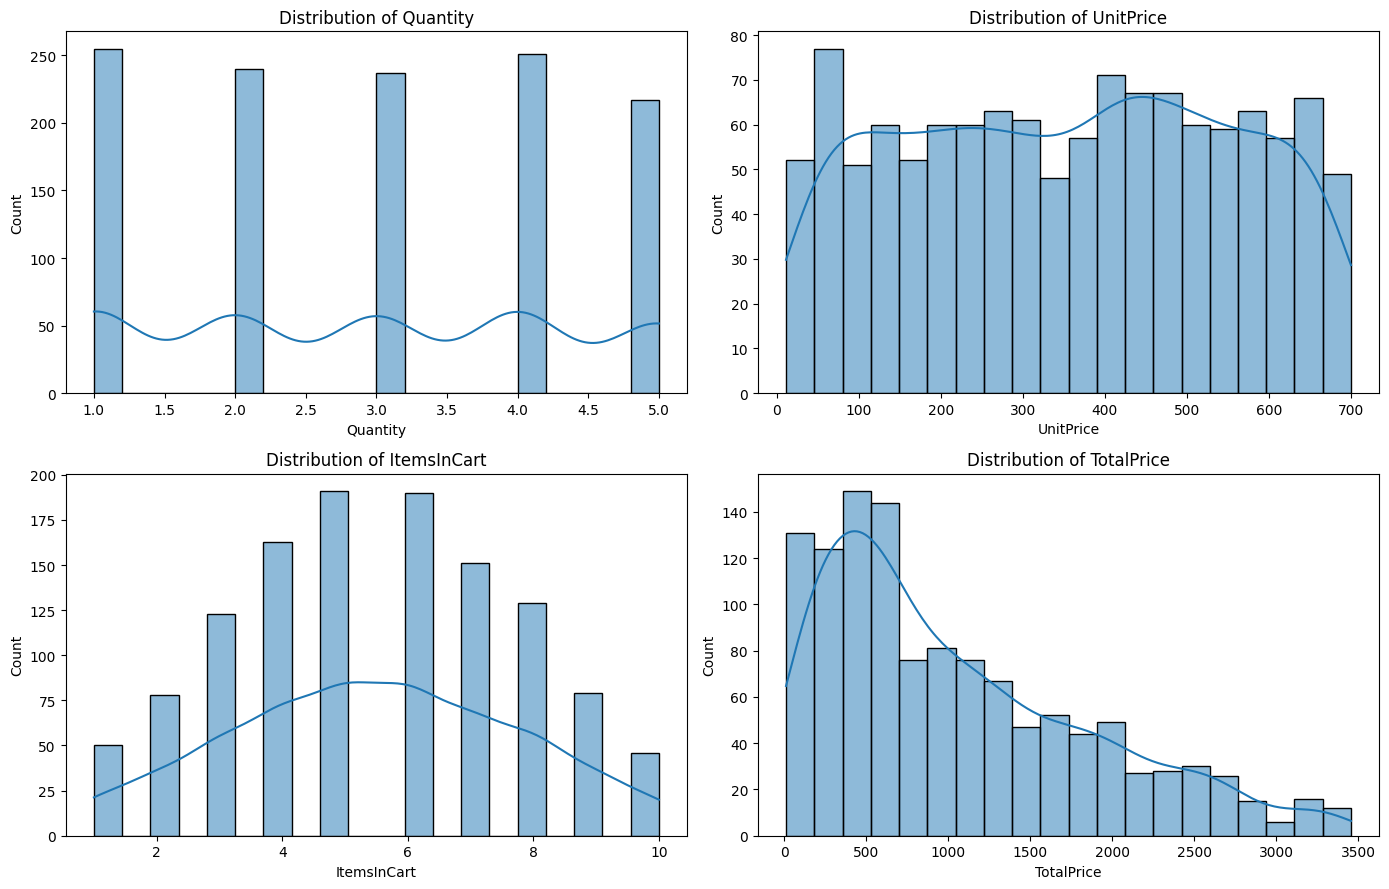

In [239]:
numeric_features = [
    "Quantity",
    "UnitPrice",
    "ItemsInCart",
    "TotalPrice"
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 9)
)

axes = axes.flatten()

for i, col in enumerate(numeric_features):

    sns.histplot(
        data=df,
        x=col,
        kde=True,
        bins = 20,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {col}")

plt.tight_layout()
plt.show()

### Categorical Feature Visualization

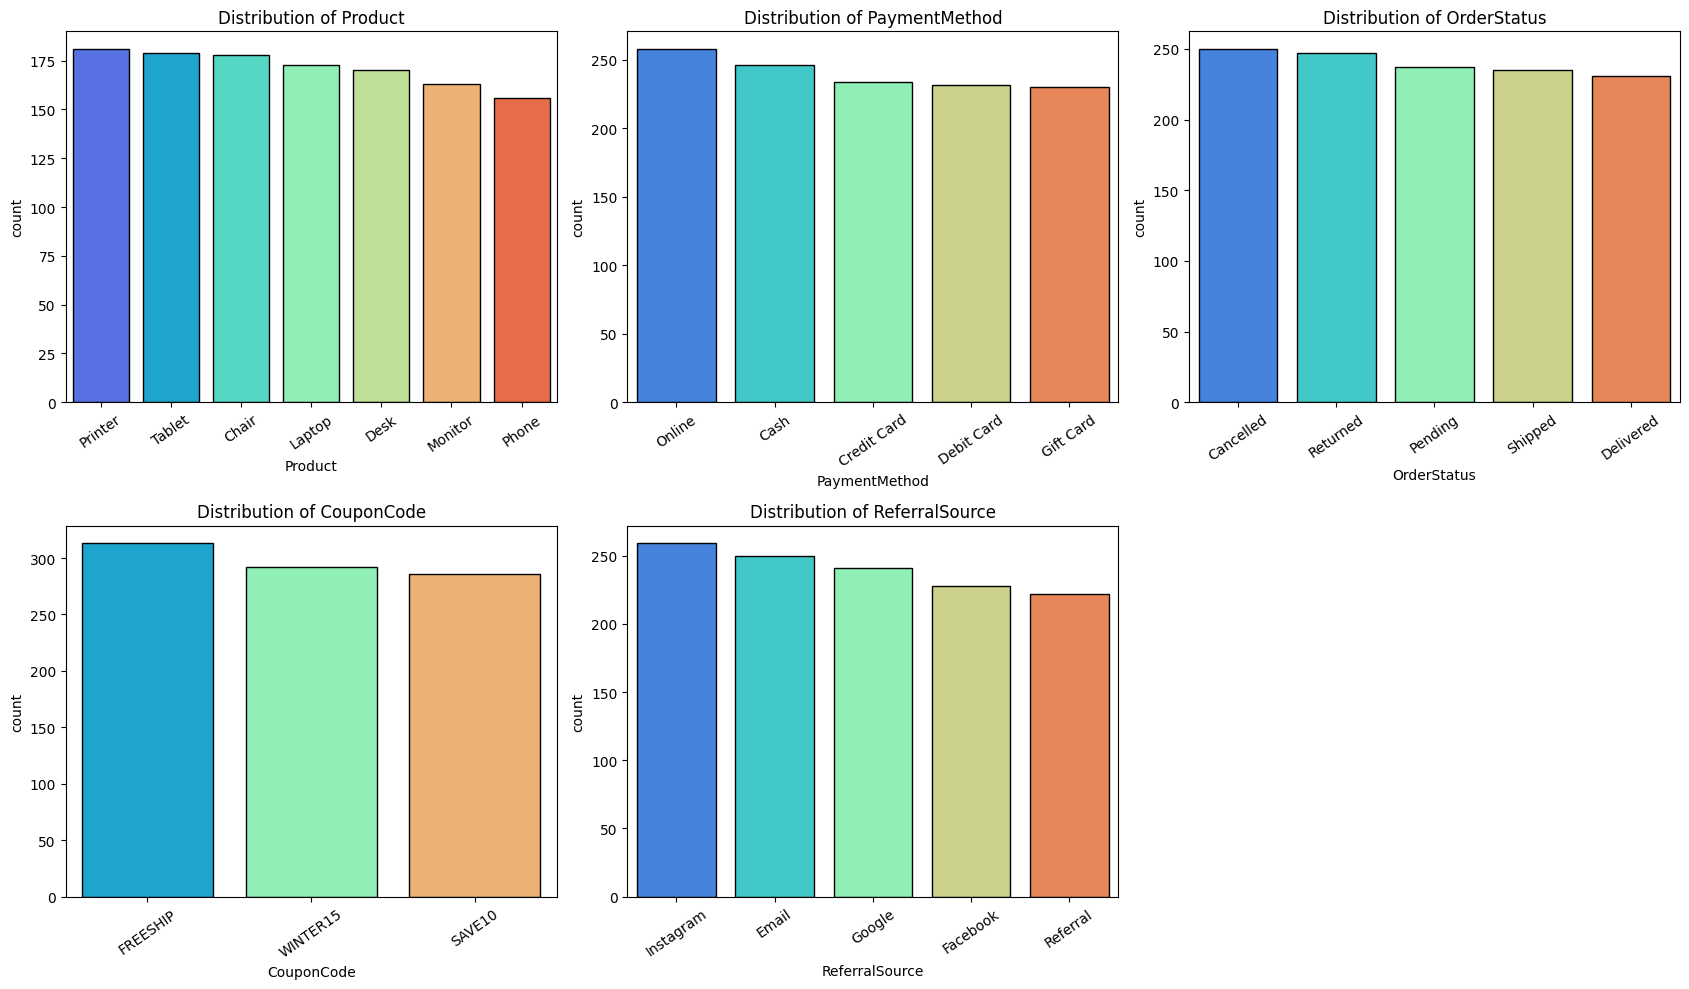

In [240]:
categorical_features = [
    "Product",
    "PaymentMethod",
    "OrderStatus",
    "CouponCode",
    "ReferralSource"
]



fig, axes = plt.subplots(
    2, 3,
    figsize=(17, 10)
)

axes = axes.flatten()

for i, col in enumerate(categorical_features):

    sns.countplot(
        data=df,
        x=col,
        ax=axes[i],
        order=df[col].value_counts().index,
        palette= 'rainbow',
        edgecolor = 'black'       
    )

    axes[i].set_title(f"Distribution of {col}")

    axes[i].tick_params(
        axis="x",
        rotation=35
    )

# Remove unused subplot
for j in range(len(categorical_features), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


### Target Feature Analysis

In [241]:
print(df["OrderStatus"].value_counts().to_frame())

print("\nPercentage Distribution:")

print(
    df["OrderStatus"].value_counts(normalize=True) * 100
)

             count
OrderStatus       
Cancelled      250
Returned       247
Pending        237
Shipped        235
Delivered      231

Percentage Distribution:
OrderStatus
Cancelled    20.833333
Returned     20.583333
Pending      19.750000
Shipped      19.583333
Delivered    19.250000
Name: proportion, dtype: float64


### Correlation Analysis

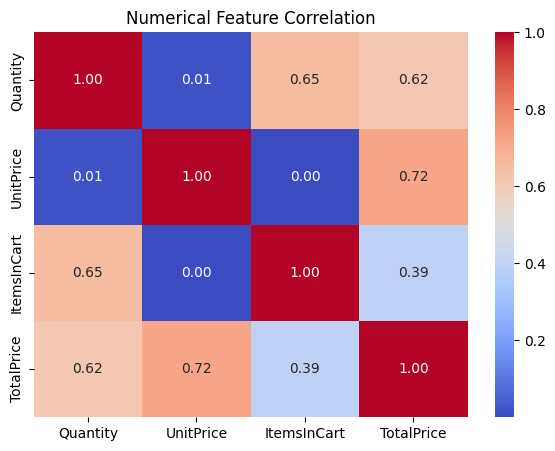

In [242]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    df[numeric_features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Numerical Feature Correlation")

plt.show()

# 3. Data Cleaning

In [243]:
# filling the missing value with most appear data
df['CouponCode'] = df['CouponCode'].fillna(df['CouponCode'].mode()[0])

df.isnull().sum()

OrderID            0
Date               0
CustomerID         0
Product            0
Quantity           0
UnitPrice          0
ShippingAddress    0
PaymentMethod      0
OrderStatus        0
TrackingNumber     0
ItemsInCart        0
CouponCode         0
ReferralSource     0
TotalPrice         0
dtype: int64

# 4. Feature Selection

In [244]:
# Select the best features
dataset = df[[
    'Product',
    'Quantity',
    'UnitPrice',
    'PaymentMethod',
    'OrderStatus',
    'ItemsInCart',
    'CouponCode',
    'ReferralSource',
    'TotalPrice'
]]


display(dataset.head(3))

print('Shape of dataset', dataset.shape)

,Product,Quantity,UnitPrice,PaymentMethod,OrderStatus,ItemsInCart,CouponCode,ReferralSource,TotalPrice
0,Monitor,5,570.62,Debit Card,Shipped,7,SAVE10,Instagram,2853.1
1,Phone,2,151.35,Online,Shipped,3,SAVE10,Referral,302.7
2,Tablet,5,550.68,Credit Card,Cancelled,8,FREESHIP,Email,2753.4


Shape of dataset (1200, 9)


# 5. Data Preprocessing

### Target Encoding

In [245]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

dataset["OrderStatus"] = label_encoder.fit_transform(
    dataset["OrderStatus"]
)

print("Target Classes:", label_encoder.classes_)

Target Classes: ['Cancelled' 'Delivered' 'Pending' 'Returned' 'Shipped']


### Features preprocessing

In [246]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = [
    "Quantity",
    "UnitPrice",
    "ItemsInCart",
    "TotalPrice"
]

categorical_features = [
    "PaymentMethod",
    "Product",
    "CouponCode",
    "ReferralSource"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

# 6. Train-Test Split

In [247]:

from sklearn.model_selection import train_test_split

X = dataset.drop(columns=['OrderStatus'])
y = dataset['OrderStatus']


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size= 0.2,
    random_state= 42,
    stratify= y
)

print("X-train shape", X_train.shape)
print("X-test shape", X_test.shape)
print("y-train shape", y_train.shape)
print("y-test shape", y_test.shape)




X-train shape (960, 8)
X-test shape (240, 8)
y-train shape (960,)
y-test shape (240,)


# 7. Model Train & Evaluation

In [248]:
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=3
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42,

    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        max_depth= 6,
        min_samples_leaf= 5
    )
}

results = []

for name, model in models.items():

    print(f"\n{'='*20} {name} {'='*20}")

    # Combine preprocessing and model
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    # Training
    pipeline.fit(X_train, y_train)

    # Prediction
    y_pred = pipeline.predict(X_test)

    # Evaluation
    accuracy = accuracy_score(y_test, y_pred)

    f1 = f1_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Weighted F1": f1
    })

    print("\nClassification Report:")
    print(
        classification_report(
            y_test,
            y_pred,
            zero_division=0
        )
    )

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, y_pred))


# Model comparison
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Weighted F1",
    ascending=False
)

print("\nModel Comparison:")
display(results_df)


==================== Logistic Regression ====================

Classification Report:
              precision    recall  f1-score   support

           0       0.22      0.20      0.21        50
           1       0.23      0.28      0.25        46
           2       0.24      0.23      0.24        47
           3       0.25      0.26      0.25        50
           4       0.17      0.15      0.16        47

    accuracy                           0.23       240
   macro avg       0.22      0.23      0.22       240
weighted avg       0.22      0.23      0.22       240


Confusion Matrix:
[[10 16  4 10 10]
 [ 7 13  9 10  7]
 [ 9  6 11 11 10]
 [ 9 10 12 13  6]
 [10 12  9  9  7]]

==================== KNN ====================

Classification Report:
              precision    recall  f1-score   support

           0       0.24      0.50      0.32        50
           1       0.16      0.20      0.18        46
           2       0.26      0.19      0.22        47
           3       0.17   

,Model,Accuracy,Weighted F1
0,Logistic Regression,0.2250,0.223174
2,Decision Tree,0.2000,0.192719
1,KNN,0.2125,0.190093
3,Random Forest,0.1875,0.188215


In [249]:
from sklearn.metrics import accuracy_score

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    train_pred = pipeline.predict(X_train)
    test_pred = pipeline.predict(X_test)

    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)

    print(f"\n{name}")
    print(f"Training Accuracy: {train_acc:.4f}")
    print(f"Testing Accuracy: {test_acc:.4f}")


Logistic Regression
Training Accuracy: 0.2812
Testing Accuracy: 0.2250

KNN
Training Accuracy: 0.5156
Testing Accuracy: 0.2125

Decision Tree
Training Accuracy: 1.0000
Testing Accuracy: 0.2000

Random Forest
Training Accuracy: 0.5979
Testing Accuracy: 0.1875
